# Project #5: Personal Finance and Expense Intelligence

---

## 1. Problem Definition
* **Business Context:** Digital payments (UPI, cards, NetBanking) make everyday spending effortless, which often leads to poor visibility over monthly cash flow, recurring bills, and impulse purchases.
* **Objective:** Build a clean, reproducible Python workflow to clean personal transaction logs, track monthly savings, detect recurring payments and spending anomalies, and recommend a realistic monthly budget.
* **Target User & Decisions:** A salaried young professional (₹80,000/month base salary) looking to control discretionary spending, flag unusual charges, and steadily raise their savings rate.

## 2. Dataset Overview
* **File:** `personal_finance_data-v2.csv` (521 raw records across Jan–Dec 2025; 507 valid records after cleaning).
* **Source & Privacy:** Synthetically generated Indian personal finance data — zero personally identifiable or confidential bank data.
* **Columns:** `date`, `merchant`, `category`, `payment_mode`, `amount` (₹), `type` (`Income` / `Expense`).
* **Limitations:** Synthetic data does not reflect tax deductions (TDS/EPF), credit card billing lags, or investment SIPs.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the raw dataset
df = pd.read_csv("personal_finance_data-v2.csv")
print("Raw shape:", df.shape)
df.head()

Raw shape: (521, 6)


,date,merchant,category,payment_mode,amount,type
0,2025-01-01,TechCorp Salary,Salary,NetBanking,80000.00,Income
1,2025-01-02,Ola,Transport,UPI,314.65,Expense
2,2025-01-02,Local Cafe,Food & Dining,UPI,775.26,Expense
3,2025-01-02,Blinkit,Groceries,UPI,501.43,Expense
4,2025-01-03,Uber,Transport,UPI,601.36,Expense


In [23]:
# Quick data quality check before cleaning
print("Duplicates:", df.duplicated().sum())
print("\nMissing values:\n", df.isna().sum())
print("\nInvalid amounts (<= 0):", (df["amount"] <= 0).sum())
print("\nRaw categories:", sorted(df["category"].dropna().unique()))

Duplicates: 10

Missing values:
 date            0
merchant        0
category        6
payment_mode    4
amount          0
type            0
dtype: int64

Invalid amounts (<= 0): 4

Raw categories: ['Entertainment', 'Food & Dining', 'Food and Dining', 'Groceries', 'Health', 'Housing', 'Online Shopping', 'Other Income', 'Salary', 'Shopping', 'Subscriptions', 'Transport', 'Travel', 'Utilities', 'groceries']


## 3. Data Cleaning & Preparation
Cleaning steps applied:
1. Drop exact duplicate rows.
2. Parse mixed date formats (`YYYY-MM-DD` and `DD/MM/YYYY`) into proper `datetime`.
3. Remove invalid amounts (`amount <= 0`).
4. Trim extra spaces and standardize merchant & category names.
5. Fill missing categories using each merchant's most frequent category, and fill missing payment modes with the overall mode.
6. Create a `month` column for time-series analysis.

In [ ]:
# 1. Remove duplicates
df = df.drop_duplicates().copy()

# 2. Treating mixed date formats safely
d1 = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce")
df["date"] = d1.fillna(d2)
df = df.dropna(subset=["date"])

# 3. Keep only valid positive amounts
df["amount"] = pd.to_numeric(df["amount"], errors="coerce")
df = df[df["amount"] > 0].copy()

# 4. Standardize merchant and category text
df["merchant"] = df["merchant"].str.strip().str.title()
df["category"] = df["category"].str.strip().replace({
    "Food and Dining": "Food & Dining",
    "groceries": "Groceries",
    "Online Shopping": "Shopping"
})

# 5. Fill missing values
merchant_cat = df.dropna(subset=["qcategory"]).groupby("merchant")["category"].agg(lambda x: x.mode()[0])
df["category"] = df["category"].fillna(df["merchant"].map(merchant_cat))
df["payment_mode"] = df["payment_mode"].fillna(df["payment_mode"].mode()[0])

# 6. Add month feature and sort by date
df["month"] = df["date"].dt.to_period("M").astype(str)
df = df.sort_values("date").reset_index(drop=True)

print("Clean shape:", df.shape)
print("Missing values left:", df.isna().sum().sum())
print("Clean categories:", sorted(df["category"].unique()))

Clean shape: (507, 7)
Missing values left: 0
Clean categories: ['Entertainment', 'Food & Dining', 'Groceries', 'Health', 'Housing', 'Other Income', 'Salary', 'Shopping', 'Subscriptions', 'Transport', 'Travel', 'Utilities']


## 4. Analysis & Visualizations

### 4.1 Monthly Cash-Flow Trend & Savings Rate

In [25]:
# Monthly income, expense, savings, and savings rate
monthly = df.pivot_table(index="month", columns="type", values="amount", aggfunc="sum", fill_value=0)
monthly["Savings"] = monthly["Income"] - monthly["Expense"]
monthly["Savings_Rate_%"] = (monthly["Savings"] / monthly["Income"] * 100).round(2)

total_income = monthly["Income"].sum()
total_expense = monthly["Expense"].sum()
total_savings = total_income - total_expense
overall_rate = total_savings / total_income * 100

print(f"Annual Income : ₹{total_income:,.0f}")
print(f"Annual Expense: ₹{total_expense:,.0f}")
print(f"Annual Savings: ₹{total_savings:,.0f} ({overall_rate:.2f}%)")
monthly.round(2)

Annual Income : ₹990,000
Annual Expense: ₹686,762
Annual Savings: ₹303,238 (30.63%)


type,Expense,Income,Savings,Savings_Rate_%
month,,,,
2025-01,49862.48,80000.0,30137.52,37.67
2025-02,49219.81,80000.0,30780.19,38.48
2025-03,49875.45,95000.0,45124.55,47.50
2025-04,74154.01,80000.0,5845.99,7.31
2025-05,50365.50,80000.0,29634.50,37.04
2025-06,54859.90,80000.0,25140.10,31.43
2025-07,51385.22,80000.0,28614.78,35.77
2025-08,63380.98,80000.0,16619.02,20.77
2025-09,56462.65,95000.0,38537.35,40.57


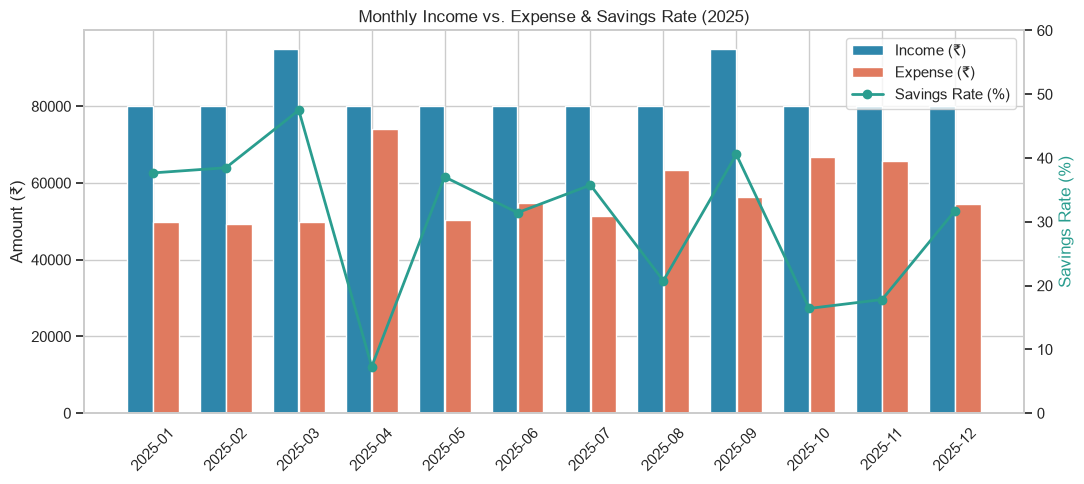

In [26]:
# Chart 1: Monthly Cash-Flow Trend
fig, ax1 = plt.subplots(figsize=(11, 5))

x = np.arange(len(monthly))
ax1.bar(x - 0.18, monthly["Income"], width=0.35, label="Income (₹)", color="#2E86AB")
ax1.bar(x + 0.18, monthly["Expense"], width=0.35, label="Expense (₹)", color="#E07A5F")
ax1.set_xticks(x)
ax1.set_xticklabels(monthly.index, rotation=45)
ax1.set_ylabel("Amount (₹)")
ax1.set_title("Monthly Income vs. Expense & Savings Rate (2025)")

ax2 = ax1.twinx()
ax2.plot(x, monthly["Savings_Rate_%"], color="#2A9D8F", marker="o", linewidth=2, label="Savings Rate (%)")
ax2.set_ylabel("Savings Rate (%)", color="#2A9D8F")
ax2.set_ylim(0, 60)
ax2.grid(False)

# Combine legends
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.show()

### 4.2 Category Spending Composition

In [27]:
# Expense breakdown by category
expenses = df[df["type"] == "Expense"].copy()

category_spend = expenses.groupby("category")["amount"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False)
category_spend["monthly_avg"] = category_spend["sum"] / 12
category_spend["share_%"] = (category_spend["sum"] / total_expense * 100).round(2)
category_spend.round(2)

,sum,count,mean,monthly_avg,share_%
category,,,,,
Housing,216000.00,12,18000.00,18000.00,31.45
Shopping,133972.37,45,2977.16,11164.36,19.51
Groceries,105694.51,128,825.74,8807.88,15.39
Food & Dining,82138.05,131,627.01,6844.84,11.96
Utilities,39928.26,24,1663.68,3327.36,5.81
Transport,37172.37,104,357.43,3097.70,5.41
Health,33500.00,13,2576.92,2791.67,4.88
Entertainment,18167.99,23,789.91,1514.00,2.65
Travel,14200.00,1,14200.00,1183.33,2.07


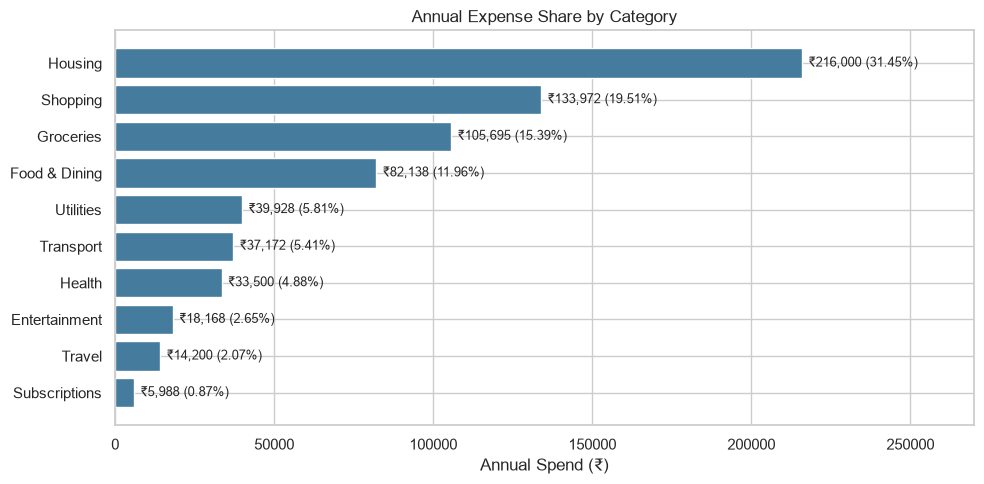

In [28]:
# Chart 2: Category Composition
plt.figure(figsize=(10, 5))
plot_data = cat_spend.sort_values("sum")
bars = plt.barh(plot_data.index, plot_data["sum"], color="#457B9D")

for bar, pct in zip(bars, plot_data["share_%"]):
    plt.text(bar.get_width() + 2000, bar.get_y() + bar.get_height()/2,
             f"₹{bar.get_width():,.0f} ({pct}%)", va="center", fontsize=9)

plt.xlim(0, plot_data["sum"].max() * 1.25)
plt.xlabel("Annual Spend (₹)")
plt.title("Annual Expense Share by Category")
plt.tight_layout()
plt.show()

### 4.3 Recurring Payments Detection
Merchants appearing in at least 10 months with roughly 1 transaction per month (`<= 14` total transactions/year) are flagged as recurring monthly commitments.

In [29]:
rec = expenses.groupby(["merchant", "category"]).agg(
    months_active=("month", "nunique"),
    txns=("amount", "count"),
    avg_amount=("amount", "mean"),
    std_amount=("amount", "std")
).reset_index()

recurring = rec[(rec["months_active"] >= 10) & (rec["txns"] <= 14)].sort_values("avg_amount", ascending=False)
print(f"Estimated Monthly Recurring Spend: ₹{recurring['avg_amount'].sum():,.2f}")
recurring.round(2)

Estimated Monthly Recurring Spend: ₹23,724.10


,merchant,category,months_active,txns,avg_amount,std_amount
9,House Rent,Housing,12,12,18000.0,0.00
6,Electricity Bill,Utilities,12,13,2226.1,1125.22
8,Gym Membership,Health,12,12,2000.0,0.00
11,Jiofiber,Utilities,11,11,999.0,0.00
15,Netflix,Subscriptions,12,12,499.0,0.00


### 4.4 Budget vs. Actual Comparison
Comparing actual monthly averages against a simple baseline monthly budget of **₹51,000**.

In [30]:
# Baseline monthly budget (₹)
budget = {
    "Housing": 18000, "Groceries": 8500, "Food & Dining": 5500,
    "Shopping": 6500, "Transport": 3500, "Utilities": 3000,
    "Health": 2500, "Entertainment": 1500, "Travel": 1500, "Subscriptions": 500
}

bva = pd.DataFrame({
    "Monthly_Budget": pd.Series(budget),
    "Actual_Avg": cat_spend["monthly_avg"]
}).fillna(0)
bva["Variance"] = bva["Actual_Avg"] - bva["Monthly_Budget"]

print(f"Total Monthly Budget: ₹{bva['Monthly_Budget'].sum():,.0f} | Actual Avg: ₹{bva['Actual_Avg'].sum():,.0f}")
bva.sort_values("Variance", ascending=False).round(2)

Total Monthly Budget: ₹51,000 | Actual Avg: ₹57,230


,Monthly_Budget,Actual_Avg,Variance
Shopping,6500,11164.36,4664.36
Food & Dining,5500,6844.84,1344.84
Utilities,3000,3327.36,327.36
Groceries,8500,8807.88,307.88
Health,2500,2791.67,291.67
Entertainment,1500,1514.00,14.00
Housing,18000,18000.00,0.00
Subscriptions,500,499.00,-1.00
Travel,1500,1183.33,-316.67
Transport,3500,3097.70,-402.30


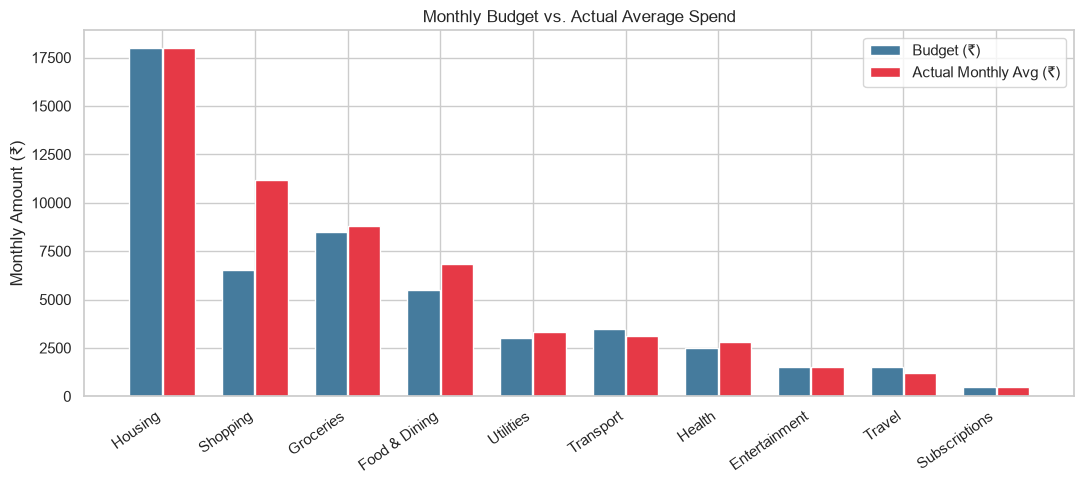

In [31]:
# Chart 3: Budget vs. Actual Comparison
bva_sorted = bva.sort_values("Actual_Avg", ascending=False)
x = np.arange(len(bva_sorted))

plt.figure(figsize=(11, 5))
plt.bar(x - 0.18, bva_sorted["Monthly_Budget"], width=0.35, label="Budget (₹)", color="#457B9D")
plt.bar(x + 0.18, bva_sorted["Actual_Avg"], width=0.35, label="Actual Monthly Avg (₹)", color="#E63946")
plt.xticks(x, bva_sorted.index, rotation=35, ha="right")
plt.ylabel("Monthly Amount (₹)")
plt.title("Monthly Budget vs. Actual Average Spend")
plt.legend()
plt.tight_layout()
plt.show()

### 4.5 Anomaly Detection (Category IQR vs. Rolling Average)
We test two simple rule-based detectors:
* **Category-Level IQR (Selected):** Flags expenses above `Q3 + 1.5 * IQR` within each category.
* **30-Transaction Rolling Mean + 2 SD (Comparison):** Flags expenses above the recent rolling average across all categories.

Category-level IQR works much better for personal finance because expense amounts are right-skewed and vary widely by category—a global rolling average mistakenly flags regular ₹18,000 rent payments as anomalies.

In [32]:
# Method 1: Category-level IQR
q1 = expenses.groupby("category")["amount"].transform(lambda x: x.quantile(0.25))
q3 = expenses.groupby("category")["amount"].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
upper_iqr = np.where(iqr > 0, q3 + 1.5 * iqr, q3 * 1.5)
expenses["iqr_anomaly"] = expenses["amount"] > upper_iqr

# Method 2: Rolling 30-transaction mean + 2 SD
roll_mean = expenses["amount"].shift(1).rolling(30, min_periods=10).mean()
roll_std = expenses["amount"].shift(1).rolling(30, min_periods=10).std()
expenses["rolling_anomaly"] = expenses["amount"] > (roll_mean + 2 * roll_std)

# Compare both methods
print("IQR Anomalies Flagged     :", expenses["iqr_anomaly"].sum())
print("Rolling Anomalies Flagged :", expenses["rolling_anomaly"].sum(),
      "(includes", (expenses[expenses["rolling_anomaly"]]["category"] == "Housing").sum(), "false-positive rent payments)")

# Display IQR anomalies table
anomalies = expenses[expenses["iqr_anomaly"]][["date", "merchant", "category", "payment_mode", "amount"]]
anomalies.sort_values("amount", ascending=False)

IQR Anomalies Flagged     : 5
Rolling Anomalies Flagged : 24 (includes 11 false-positive rent payments)


,date,merchant,category,payment_mode,amount
150,2025-04-20,Amazon,Shopping,Credit Card,24999.0
409,2025-10-22,Flipkart,Shopping,Credit Card,16500.0
308,2025-08-15,Apollo Hospital,Health,Credit Card,9500.0
496,2025-12-24,Taj Restaurant,Food & Dining,Credit Card,6200.0
227,2025-06-12,Electricity Bill,Utilities,UPI,5800.0


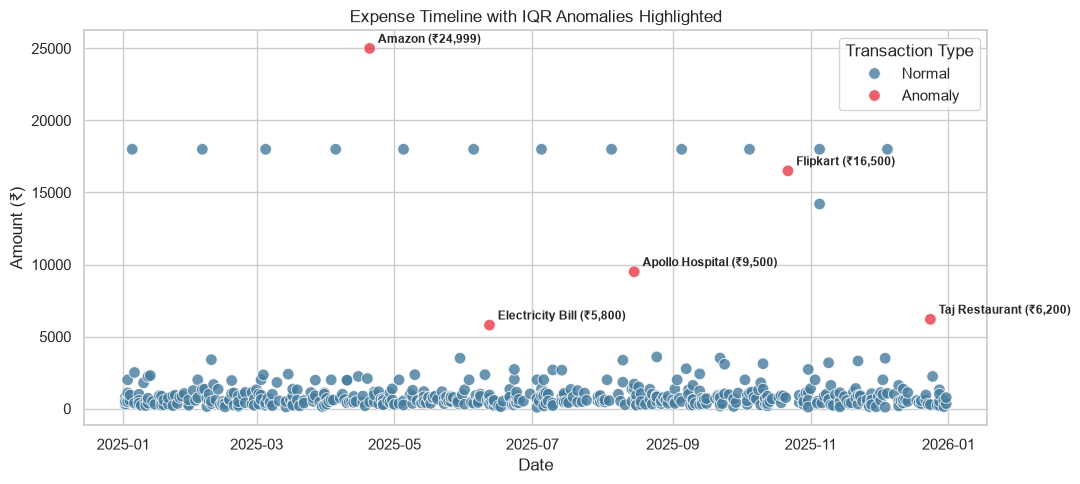

In [33]:
# Chart 4: Anomaly Scatter Plot (Seaborn)
expenses["status"] = np.where(expenses["iqr_anomaly"], "Anomaly", "Normal")

plt.figure(figsize=(11, 5))
sns.scatterplot(
    data=expenses,
    x="date",
    y="amount",
    hue="status",
    palette={"Normal": "#457B9D", "Anomaly": "#E63946"},
    s=70,
    alpha=0.8
)

# Annotate flagged anomalies
for _, row in expenses[expenses["iqr_anomaly"]].iterrows():
    plt.annotate(
        f"{row['merchant']} (₹{row['amount']:,.0f})",
        (row["date"], row["amount"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold"
    )

plt.xlabel("Date")
plt.ylabel("Amount (₹)")
plt.title("Expense Timeline with IQR Anomalies Highlighted")
plt.legend(title="Transaction Type")
plt.tight_layout()
plt.show()

### 4.6 Sensitivity Check: Trimming Discretionary Spend
Testing how cutting **Shopping, Food & Dining, and Entertainment** by 10%, 15%, and 20% changes annual savings.

In [34]:
disc_cats = ["Shopping", "Food & Dining", "Entertainment"]
disc_total = expenses[expenses["category"].isin(disc_cats)]["amount"].sum()

for cut in [0.10, 0.15, 0.20]:
    extra = disc_total * cut
    new_rate = (total_savings + extra) / total_income * 100
    print(f"{int(cut*100)}% Cut -> Extra Savings: ₹{extra:,.0f}/year | New Savings Rate: {new_rate:.2f}%")

10% Cut -> Extra Savings: ₹23,428/year | New Savings Rate: 33.00%
15% Cut -> Extra Savings: ₹35,142/year | New Savings Rate: 34.18%
20% Cut -> Extra Savings: ₹46,856/year | New Savings Rate: 35.36%


## 5. Key Findings
1. **Top 4 Categories Account for 78.3% of Spending:** Out of ₹6,86,762 in annual expenses (vs. ₹9,90,000 income; **30.63% savings rate**), **Housing (31.45%)**, **Shopping (19.51%)**, **Groceries (15.39%)**, and **Food & Dining (11.96%)** dominate cash outflows.
2. **One-Off Spikes Drive Monthly Volatility:** While typical months achieve a 31%–38% savings rate, April dropped to **7.31%** (₹24,999 Amazon order) and October–November fell to **16%–18%** (festive Flipkart spend and Diwali travel).
3. **Recurring Bills Take Up ~30% of Base Salary:** Five recurring obligations (**House Rent ₹18,000**, **Electricity ~₹2,226**, **Gym ₹2,000**, **JioFiber ₹999**, **Netflix ₹499**) total **₹23,724/month** (~29.7% of the ₹80,000 base salary).
4. **Budget Overruns Come Mainly from Shopping & Dining:** Actual monthly spending averaged **₹57,230** vs. the **₹51,000** budget (+₹6,230 overrun). **Shopping (+₹4,664/month)** and **Food & Dining (+₹1,345/month)** account for almost the entire deficit.
5. **Category IQR Beats Rolling Averages:** Category-level IQR cleanly flagged **5 genuine anomalies** (₹24,999 Amazon, ₹16,500 Flipkart, ₹9,500 Apollo Hospital, ₹6,200 Taj Restaurant, ₹5,800 Electricity spike), whereas the rolling average falsely flagged **11 monthly rent transfers**.
6. **Realistic Cuts Boost Savings Meaningfully:** A 15% trim on just Shopping, Food & Dining, and Entertainment saves **₹35,142/year**, lifting the savings rate from **30.63% to 34.18%**.

## 6. Budget Recommendation & Action Plan
**Assumptions:** Base salary stays ₹80,000/month; fixed rent and essential groceries/utilities remain stable; irregular big-ticket shopping and travel are funded via monthly sinking funds.

* **Proposed Monthly Operating Budget: ₹54,000/month** (saves ₹3,230/month or ~₹38,760/year over historical averages):
  * **Keep Fixed/Essential Caps:** Housing ₹18,000, Groceries ₹8,500, Utilities ₹3,300, Transport ₹3,100, Health ₹2,500, Subscriptions ₹500.
  * **Control Discretionary Buckets:** Cap **Food & Dining at ₹5,500** (~₹1,375/week on Swiggy/Zomato) and **Entertainment at ₹1,500**.
  * **Use Sinking Funds for Spikes:** Set aside **₹2,500/month** for big-ticket shopping/festivals (plus ₹6,000 routine shopping = ₹8,500 total) and **₹1,500/month** for Travel so one-off months never wipe out monthly savings.
  * **Automate Savings:** Transfer **₹26,000** to savings/SIPs on the 2nd of each month right after salary credit.

## 7. Limitations & Ethics
* **Synthetic Data:** Useful for privacy-safe prototyping, but real banking data contains refunds, split UPI bills, and irregular cash withdrawals.
* **Sparse Categories in IQR:** Because `Travel` had only 1 transaction (₹14,200), its IQR is 0 and it is not flagged as a category outlier—showing why statistical rules should be paired with a sinking-fund budget.
* **Privacy:** If adapted to real bank statements, files should stay local and anonymized without uploading account numbers or personal descriptions to external services.

## 8. References
1. **Dataset:** `personal_finance_data-v2.csv` (synthetic 2025 Indian personal finance dataset, 521 raw records).
2. **Python Libraries:** `pandas`, `NumPy`, `Matplotlib`, and `Seaborn` official documentation.